# PAGR: a reproducible development record

This notebook separates archived evidence from fresh execution. PAGR is a provisional research direction, not a validated superior algorithm or a new HJBI PDE. All seven methods and all three reused seeds are shown. No engineered terminal-gradient corruption is added to these toy tasks.

The true control objective stays fixed. Actor updates use lean adjoints and learned terminal gradients; truth is available only for generating offline observations, evaluation, and diagnostics. See `docs/settings.md`, `docs/methods.md`, and `docs/results.md` for precise assumptions.

In [1]:
from pathlib import Path
import json, tempfile, platform
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from pagr import runtime as rt

print({'python': platform.python_version(), 'torch': torch.__version__, 'numpy': np.__version__})
print(rt.verify())
data = rt.summary()
assert data['training_runs'] == 42


{'python': '3.13.11', 'torch': '2.9.1', 'numpy': '2.3.5'}
{'verified_files': 218, 'status': 'ok', 'note': 'Integrity is not algorithm efficacy. Historical solver warnings remain in the reference audit.'}


## 1. All archived results (not a fresh experiment)

Costs are averaged over three training seeds. Within-seed final evaluation uses 4096 paths. These paths do not increase the number of independent training seeds. Positive reduction means a lower cost than the original AM baseline.

In [2]:
rows = ['| Task | Method | Mean true cost | Reduction (%) | Wins / 3 |', '|---|---|---:|---:|---:|']
for task, methods in data['tasks'].items():
    for method, row in methods.items():
        rows.append(f"| {task} | {method} | {row['mean']:.6f} | {row['reduction_pct']:+.3f} | {row['wins']} |")
display(Markdown('\n'.join(rows)))


| Task | Method | Mean true cost | Reduction (%) | Wins / 3 |
|---|---|---:|---:|---:|
| navigation | am_adam | 19.467734 | -0.000 | 0 |
| navigation | am_2x | 19.413852 | +0.277 | 2 |
| navigation | nominal_guard | 19.612436 | -0.743 | 0 |
| navigation | robust_guard | 19.642161 | -0.896 | 0 |
| navigation | smooth | 19.316217 | +0.778 | 1 |
| navigation | residual | 19.364881 | +0.528 | 2 |
| navigation | silu | 20.175479 | -3.635 | 0 |
| arm | am_adam | 10.973526 | -0.000 | 0 |
| arm | am_2x | 10.809225 | +1.497 | 3 |
| arm | nominal_guard | 11.095938 | -1.116 | 0 |
| arm | robust_guard | 11.209811 | -2.153 | 0 |
| arm | smooth | 13.045337 | -18.880 | 0 |
| arm | residual | 11.017859 | -0.404 | 1 |
| arm | silu | 10.688394 | +2.598 | 2 |

## 2. Learning curves, actual checkpoint trajectories, and aggregate costs

Left: all navigation learning curves from the archived runs (mean over seeds). Middle: freshly simulated paths from archived final navigation actors, seed 18001, with identical Brownian streams; the first eight paths are shown without selecting successful ones. Right: all arm method means and all three seed points. Soft obstacle penalties do not impose hard safety guarantees.

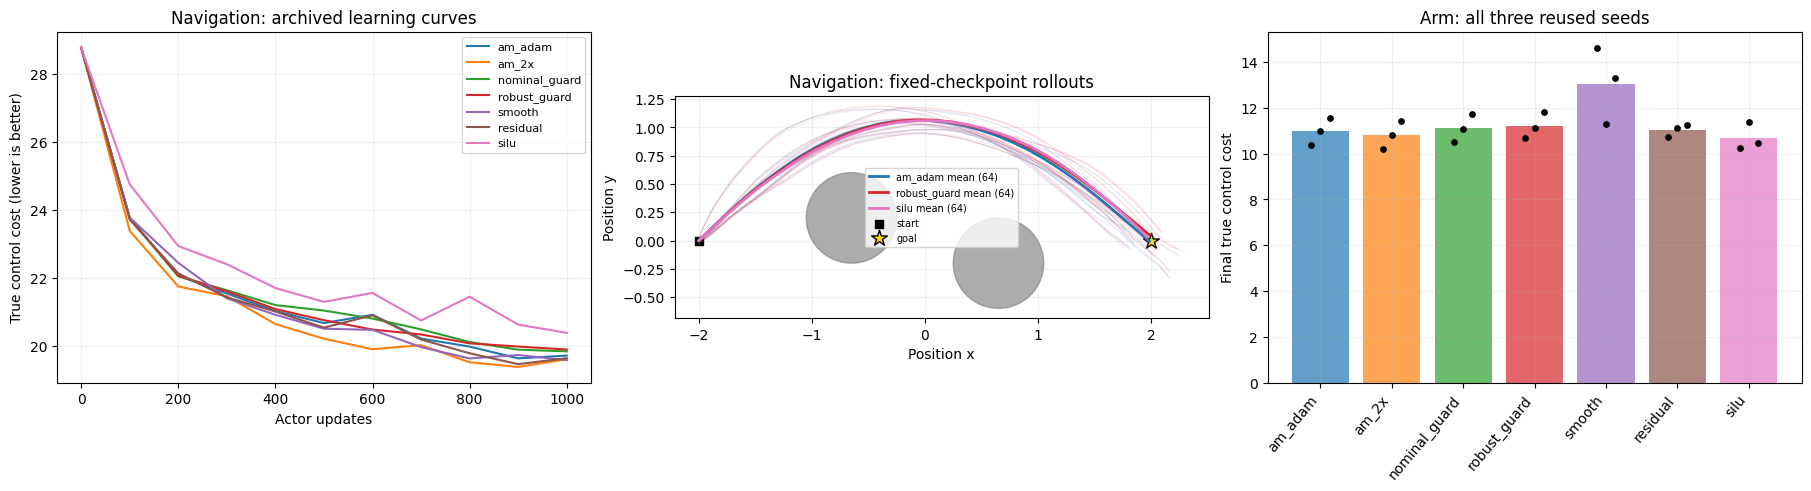

In [3]:
la, aa, sn, vg = rt.backend()
task_module, cfg, _, _, _ = la.load_inputs('navigation', 18001)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)
colors = dict(zip(rt.METHODS, plt.get_cmap('tab10').colors))
for method in rt.METHODS:
    histories = [rt.reference('navigation', seed, method)['history'] for seed in rt.SEEDS]
    steps = [point['step'] for point in histories[0]]
    costs = np.asarray([[point['cost'] for point in h] for h in histories])
    axes[0].plot(steps, costs.mean(0), label=method, color=colors[method])
axes[0].set(title='Navigation: archived learning curves', xlabel='Actor updates', ylabel='True control cost (lower is better)')
axes[0].legend(fontsize=8)
for method in ('am_adam', 'robust_guard', 'silu'):
    actor = task_module.Controller(cfg.actor_width)
    checkpoint = rt.ASSETS / 'reference/followup/navigation/seed_18001' / method / 'actor.pt'
    actor.load_state_dict(torch.load(checkpoint, weights_only=True))
    paths, _ = task_module.rollout(actor, cfg, 64, task_module.rng(18001 + 600000))
    for path in paths[:8].numpy():
        axes[1].plot(path[:, 0], path[:, 1], color=colors[method], alpha=.18, lw=.8)
    mean = paths.mean(0).numpy()
    axes[1].plot(mean[:, 0], mean[:, 1], color=colors[method], lw=2, label=method + ' mean (64)')
for x, y, r in cfg.obstacles:
    axes[1].add_patch(plt.Circle((x, y), r, color='gray', alpha=.65))
axes[1].scatter([cfg.start[0]], [cfg.start[1]], marker='s', c='black', label='start')
axes[1].scatter([cfg.goal[0]], [cfg.goal[1]], marker='*', c='gold', edgecolors='black', s=140, label='goal')
axes[1].set(title='Navigation: fixed-checkpoint rollouts', xlabel='Position x', ylabel='Position y', aspect='equal')
axes[1].legend(fontsize=7)
for i, method in enumerate(rt.METHODS):
    row = data['tasks']['arm'][method]
    axes[2].bar(i, row['mean'], color=colors[method], alpha=.7)
    axes[2].scatter(i + np.array([-.13, 0, .13]), row['costs'], c='black', s=15, zorder=3)
axes[2].set_xticks(range(len(rt.METHODS)), rt.METHODS, rotation=50, ha='right')
axes[2].set(title='Arm: all three reused seeds', ylabel='Final true control cost')
for ax in axes: ax.grid(alpha=.2)
plt.show()


## 3. Fresh training, not a copied result

Run the full 1000-update baseline and SiLU ablation for arm seed 18001. This seed was selected for a compact reproducibility example, not the largest observed gain (which was seed 18003). Both use the bundled fixed offline inputs; no extra true terminal observations are queried by the actor. Cross-platform differences are reported, not hidden.

In [4]:
Path('runs').mkdir(exist_ok=True)
run_root = Path(tempfile.mkdtemp(prefix='notebook-', dir='runs'))
fresh = []
for method in ('am_adam', 'silu'):
    fresh.append(rt.replay('arm', 18001, method, run_root / method))
for result in fresh:
    print({key: result[key] for key in ('task', 'seed', 'method', 'final', 'cost_error', 'max_final_metric_error', 'exact')})


arm 18001 am_adam cost 10.392496109008789 seconds 4.108283207984641


arm 18001 am_adam 0.3 J 10.256926 seconds 4.3


{'task': 'arm', 'seed': 18001, 'method': 'am_adam', 'final': {'cost': 10.392496109008789, 'cost_mc_se': 0.07162398844957352, 'terminal': 6.925909042358398, 'energy': 3.4665865898132324, 'running': 0.0, 'success': 0.11669921875, 'collision': 0.0, 'distance': 0.5078998804092407, 'orientation_error': 0.5333571434020996}, 'cost_error': 0.0, 'max_final_metric_error': 0.0, 'exact': True}
{'task': 'arm', 'seed': 18001, 'method': 'silu', 'final': {'cost': 10.256925582885742, 'cost_mc_se': 0.06869642436504364, 'terminal': 6.516666889190674, 'energy': 3.74025821685791, 'running': 0.0, 'success': 0.1630859375, 'collision': 0.0, 'distance': 0.4815406799316406, 'orientation_error': 0.5165051817893982}, 'cost_error': 0.0, 'max_final_metric_error': 0.0, 'exact': True}


## 4. Frozen-path gradient mechanism diagnostics (archived)

These probes use common original-AM checkpoints, not each method's own policy distribution. They are evaluation-only observations. Lean matching parameter gradients are not generally true-J gradients. Similar value error and different terminal/propagated error coexist, but the full causal claim remains unproven; the value error here is about 21%, not near-perfect.

In [5]:
mechanism = json.loads((rt.ASSETS / 'reference/mechanism.json').read_text())
metrics = ('value_relative_rms_error', 'terminal_gradient_relative_error', 'lean_q_relative_error', 'lean_q_cosine', 'shared_history_Adam_step_relative_error', 'shared_history_Adam_step_cosine')
rows = ['| Arm diagnostic | Original | SiLU |', '|---|---:|---:|']
for metric in metrics:
    means = [np.mean([row[metric] for row in mechanism['rows'] if row['task'] == 'arm' and row['method'] == method]) for method in ('original', 'silu')]
    rows.append(f'| {metric} | {means[0]:.6f} | {means[1]:.6f} |')
display(Markdown('\n'.join(rows)))
print(mechanism['boundary'])


| Arm diagnostic | Original | SiLU |
|---|---:|---:|
| value_relative_rms_error | 0.214854 | 0.214489 |
| terminal_gradient_relative_error | 0.328274 | 0.235331 |
| lean_q_relative_error | 0.745226 | 0.573662 |
| lean_q_cosine | 0.641817 | 0.818089 |
| shared_history_Adam_step_relative_error | 0.306537 | 0.245857 |
| shared_history_Adam_step_cosine | 0.948382 | 0.936584 |

Evaluation-only, six common original-AM checkpoint probes per task. Same history Adam moments, fresh paths; not true-J gradients, causal mediation, or uncertainty calibration.


## 5. Integrity is not efficacy; numerical warnings remain

Software integrity tests do not turn a negative research experiment into a positive one. The historical delivery audit intentionally retains its failed overall numerical status. The selected empirical model-cost nonincrease checks are not true-cost descent guarantees.

In [6]:
audit = json.loads((rt.ASSETS / 'reference/delivery_audit.json').read_text())
print({'overall_audit_passed': audit['passed'], 'required_integrity_checks': audit['passed_required_integrity_checks'], 'solver_warnings': len(audit['solver_warnings']), 'selected_empirical_nonincrease': audit['certified_selected_empirical_nonincrease']})
assert audit['passed'] is False
assert len(audit['solver_warnings']) == 6
display(Markdown('**Conclusion:** no new candidate passes the recorded development gate. The strongest local SiLU result is task-dependent and uses reused seeds. This notebook reproduces evidence; it does not establish novelty, uncertainty calibration, or a new HJBI theorem.'))


{'overall_audit_passed': False, 'required_integrity_checks': True, 'solver_warnings': 6, 'selected_empirical_nonincrease': 300}


**Conclusion:** no new candidate passes the recorded development gate. The strongest local SiLU result is task-dependent and uses reused seeds. This notebook reproduces evidence; it does not establish novelty, uncertainty calibration, or a new HJBI theorem.